# Experiment 004: 3B base-to-GRPO analysis plots (RQ3)

This notebook compares `004_COLAB_FULL_B3_base_grpo_seed0` against
`003_COLAB_FULL_B3_sft_grpo_seed0` on the same 3B model, seed and held-out MMLU items.
It answers RQ3: does prior GSM8K SFT help or hinder GRPO?

The notebook reads only saved JSON and JSONL artifacts. It does not need a GPU.
Figures are saved to `analysis/figures/004_1/` as 300 dpi PNG files.

In [1]:
# find the repo root and load 003 and 004 results once
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("I could not find the repository root containing config.py")
sys.path.insert(0, str(ROOT))

RES = ROOT / "results"
R3 = RES / "003_COLAB_FULL_B3_sft_grpo_seed0"
B3 = RES / "base_evals" / "003_COLAB_FULL_B3"
R4 = RES / "004_COLAB_FULL_B3_base_grpo_seed0"
B4 = RES / "base_evals" / "004_COLAB_FULL_B3"
FIG = ROOT / "analysis" / "figures" / "004_1"
FIG.mkdir(parents=True, exist_ok=True)

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    xs = [row["step"] for row in trainlog if key in row and "step" in row]
    ys = [row[key] for row in trainlog if key in row and "step" in row]
    return np.asarray(xs), np.asarray(ys, dtype=float)

def smooth(values, window=15):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def load_003():
    return {
        "g": jload(R3 / "grpo_trainlog.json"),
        "eval": {
            "base": jload(B3 / "base_eval.json"),
            "sft": jload(R3 / "sft_eval.json"),
            "sft_grpo": jload(R3 / "grpo_eval.json"),
        },
        "lp": {
            "base": jload(B3 / "base_logprob.json"),
            "sft": jload(R3 / "sft_logprob.json"),
            "sft_grpo": jload(R3 / "grpo_logprob.json"),
        },
        "preds": {
            "base": jsonl(B3 / "base_preds.jsonl"),
            "sft": jsonl(R3 / "sft_preds.jsonl"),
            "sft_grpo": jsonl(R3 / "grpo_preds.jsonl"),
        },
        "lp_preds": {
            "base": jsonl(B3 / "base_logprob_preds.jsonl"),
            "sft": jsonl(R3 / "sft_logprob_preds.jsonl"),
            "sft_grpo": jsonl(R3 / "grpo_logprob_preds.jsonl"),
        },
        "man": jload(R3 / "manifest.json"),
    }

def load_004():
    return {
        "g": jload(R4 / "grpo_trainlog.json"),
        "eval": {
            "base": jload(B4 / "base_eval.json"),
            "base_grpo": jload(R4 / "grpo_eval.json"),
        },
        "lp": {
            "base": jload(B4 / "base_logprob.json"),
            "base_grpo": jload(R4 / "grpo_logprob.json"),
        },
        "preds": {
            "base": jsonl(B4 / "base_preds.jsonl"),
            "base_grpo": jsonl(R4 / "grpo_preds.jsonl"),
        },
        "lp_preds": {
            "base": jsonl(B4 / "base_logprob_preds.jsonl"),
            "base_grpo": jsonl(R4 / "grpo_logprob_preds.jsonl"),
        },
        "man": jload(R4 / "manifest.json"),
    }

def overall(D, condition, probe=False):
    bucket = "lp_preds" if probe else "preds"
    return float(np.mean([row["correct"] for row in D[bucket][condition]]))

def paired_correct(rows_a, rows_b, tier=None):
    if tier is not None:
        rows_a = [row for row in rows_a if row["tier"] == tier]
        rows_b = [row for row in rows_b if row["tier"] == tier]
    if len(rows_a) != len(rows_b):
        raise ValueError("I found different numbers of paired predictions")
    for a, b in zip(rows_a, rows_b):
        if (a["subject"], a["tier"], a["gold"]) != (b["subject"], b["tier"], b["gold"]):
            raise ValueError("I found predictions that are not aligned")
    return [bool(row["correct"]) for row in rows_a], [bool(row["correct"]) for row in rows_b]

D3 = load_003()
D4 = load_004()
TIERS = ["easy", "medium", "hard"]
GROUPS = TIERS + ["overall"]
paired_correct(D3["preds"]["sft_grpo"], D4["preds"]["base_grpo"])
print("loaded aligned 003 and 004 artifacts")
print("figures ->", FIG)

loaded aligned 003 and 004 artifacts
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/004_1


## 1. GRPO training dynamics

The two runs use the same GRPO protocol. Their only substantive difference is the starting
policy: experiment 003 starts from the SFT adapter, while experiment 004 starts from the
pretrained base model.

saved fig01_grpo_rewards_003_vs_004


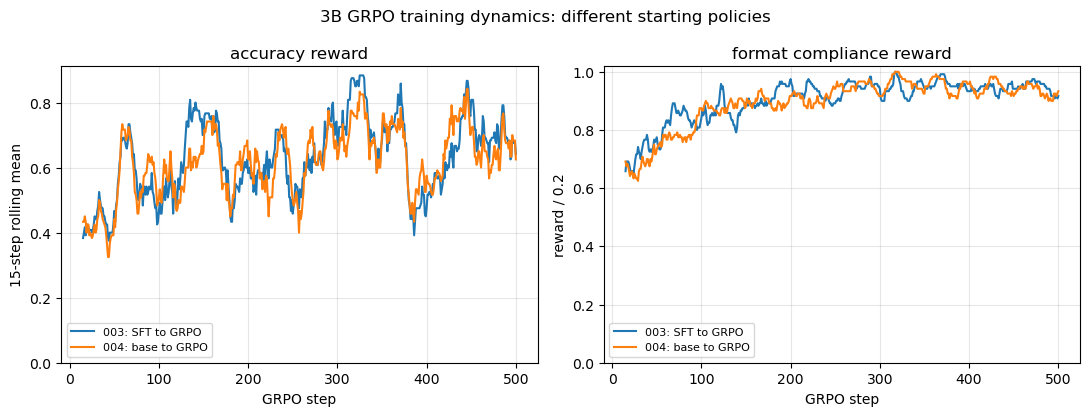

In [2]:
# compare accuracy and format reward between both 3b runs
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
window = 15
for D, label in [(D3, "003: SFT to GRPO"), (D4, "004: base to GRPO")]:
    x, y = series(D["g"], "rewards/accuracy_reward/mean")
    axes[0].plot(x[window - 1:], smooth(y, window), label=label)
    x, y = series(D["g"], "rewards/format_reward/mean")
    axes[1].plot(x[window - 1:], smooth(y, window) / 0.2, label=label)
axes[0].set_title("accuracy reward"); axes[0].set_ylabel("15-step rolling mean")
axes[1].set_title("format compliance reward"); axes[1].set_ylabel("reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step"); ax.set_ylim(bottom=0); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("3B GRPO training dynamics: different starting policies")
fig.tight_layout()
save(fig, "fig01_grpo_rewards_003_vs_004")
plt.show()

saved fig02_kl_003_vs_004


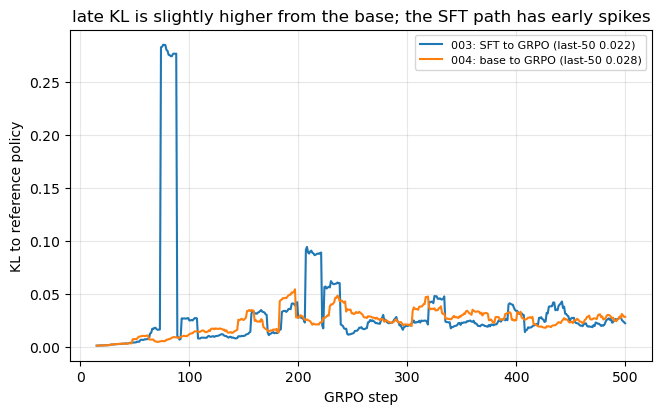

In [ ]:
# use the last 50 steps here because single kl values are noisy
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for D, label in [(D3, "003: SFT to GRPO"), (D4, "004: base to GRPO")]:
    x, y = series(D["g"], "kl")
    late = float(np.mean(y[-50:]))
    ax.plot(x[14:], smooth(y), label=f"{label} (last-50 {late:.3f})")
ax.set_xlabel("GRPO step"); ax.set_ylabel("KL to reference policy")
ax.set_title("late KL is slightly higher from the base; the SFT path has early spikes")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
save(fig, "fig02_kl_003_vs_004")
plt.show()

saved fig03_length_clipping_003_vs_004


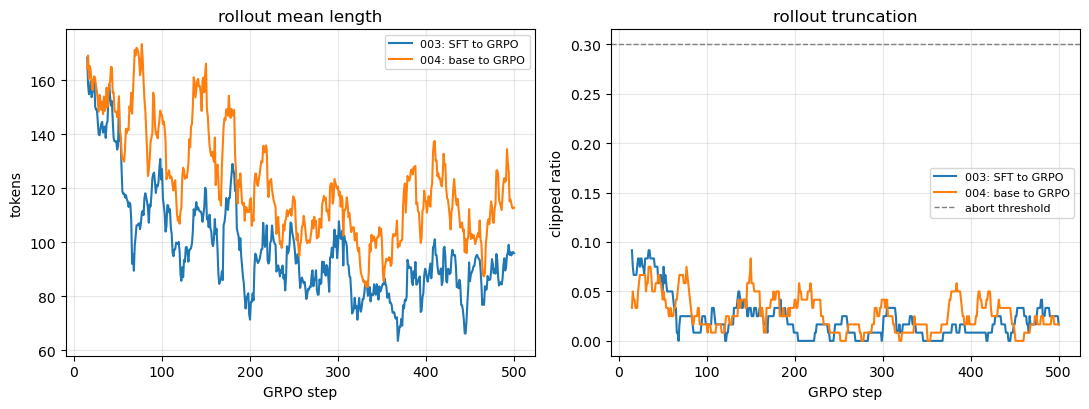

In [4]:
# check lengths and clipping to see if truncation explains the result
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for D, label in [(D3, "003: SFT to GRPO"), (D4, "004: base to GRPO")]:
    x, y = series(D["g"], "completions/mean_length")
    axes[0].plot(x[14:], smooth(y), label=label)
    x, y = series(D["g"], "completions/clipped_ratio")
    axes[1].plot(x[14:], smooth(y), label=label)
axes[1].axhline(0.3, color="grey", ls="--", lw=1, label="abort threshold")
axes[0].set_title("rollout mean length"); axes[0].set_ylabel("tokens")
axes[1].set_title("rollout truncation"); axes[1].set_ylabel("clipped ratio")
for ax in axes:
    ax.set_xlabel("GRPO step"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig03_length_clipping_003_vs_004")
plt.show()

## 2. RQ3 headline: does prior SFT help or hinder GRPO?

The clean comparison is between the two final GRPO endpoints. They use the same model scale,
seed, test items and evaluation protocol. Intermediate base and SFT generations are included
only to show the route each pipeline takes.

Interpretation must retain the one-seed caveat. At 3B seed 0, prior SFT helps GRPO overall,
easy and medium, while the hard-tier difference is not statistically distinguishable.

saved fig04_pipeline_progression


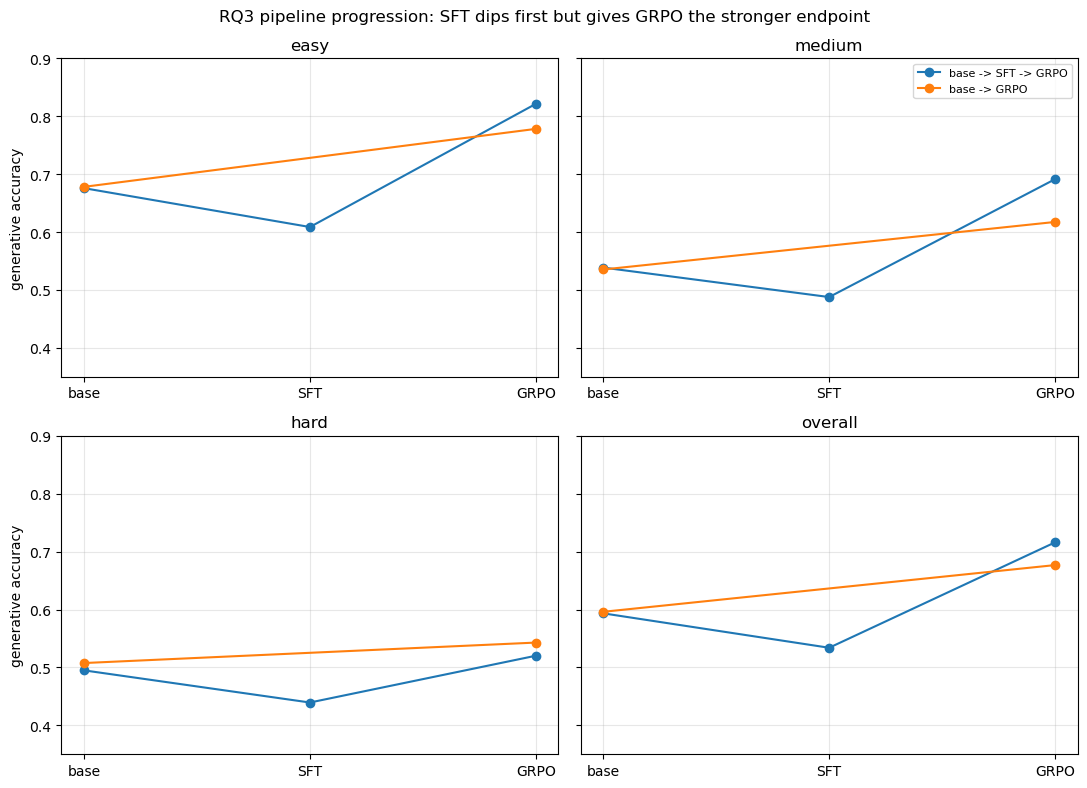

In [5]:
# plot both routes from base to the final grpo model
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, group in zip(axes.flat, GROUPS):
    if group == "overall":
        sft_path = [overall(D3, "base"), overall(D3, "sft"), overall(D3, "sft_grpo")]
        direct_path = [overall(D4, "base"), np.nan, overall(D4, "base_grpo")]
    else:
        sft_path = [D3["eval"][c]["per_tier_acc"][group] for c in ["base", "sft", "sft_grpo"]]
        direct_path = [D4["eval"]["base"]["per_tier_acc"][group], np.nan,
                       D4["eval"]["base_grpo"]["per_tier_acc"][group]]
    ax.plot([0, 1, 2], sft_path, "o-", label="base -> SFT -> GRPO")
    ax.plot([0, 2], [direct_path[0], direct_path[2]], "o-", label="base -> GRPO")
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["base", "SFT", "GRPO"])
    ax.set_title(group); ax.grid(alpha=0.3); ax.set_ylim(0.35, 0.9)
axes[0, 0].set_ylabel("generative accuracy"); axes[1, 0].set_ylabel("generative accuracy")
axes[0, 1].legend(fontsize=8)
fig.suptitle("RQ3 pipeline progression: SFT dips first but gives GRPO the stronger endpoint")
fig.tight_layout()
save(fig, "fig04_pipeline_progression")
plt.show()

saved fig05_rq3_endpoint_accuracy


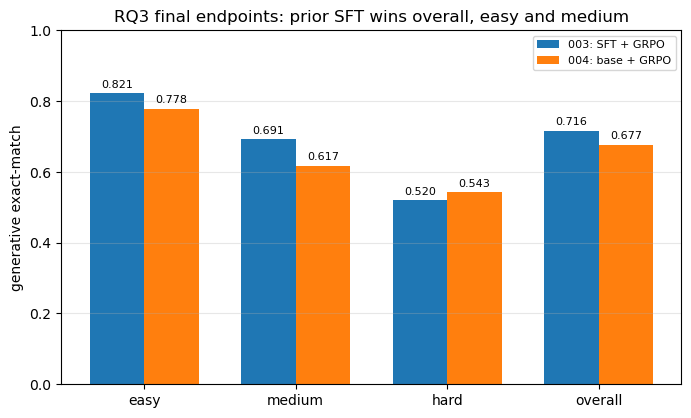

In [6]:
# compare both final grpo models and add the overall score
def gen_values(D, condition):
    return [D["eval"][condition]["per_tier_acc"][tier] for tier in TIERS] + [overall(D, condition)]

xpos = np.arange(len(GROUPS)); width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, (D, condition, label) in enumerate([
    (D3, "sft_grpo", "003: SFT + GRPO"),
    (D4, "base_grpo", "004: base + GRPO"),
]):
    values = gen_values(D, condition)
    bars = ax.bar(xpos + (i - 0.5) * width, values, width, label=label)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}",
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(xpos); ax.set_xticklabels(GROUPS); ax.set_ylim(0, 1)
ax.set_ylabel("generative exact-match")
ax.set_title("RQ3 final endpoints: prior SFT wins overall, easy and medium")
ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
save(fig, "fig05_rq3_endpoint_accuracy")
plt.show()

saved fig06_rq3_delta_ci


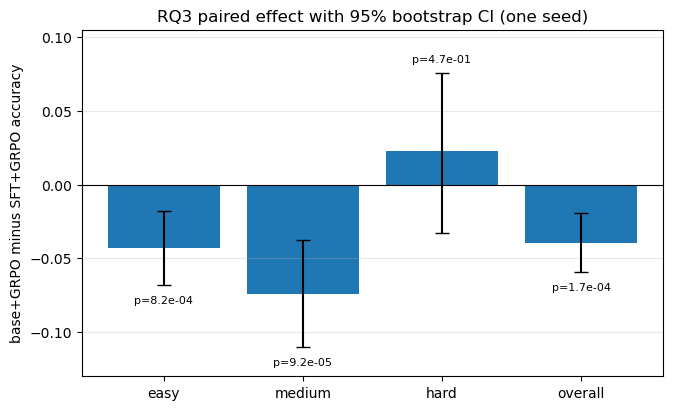

In [7]:
# calculate the paired rq3 delta, bootstrap ci and exact mcnemar p
from analysis.stats import mcnemar_exact, paired_delta_ci

rq3_stats = []
for group in GROUPS:
    tier = None if group == "overall" else group
    a, b = paired_correct(D3["preds"]["sft_grpo"], D4["preds"]["base_grpo"], tier=tier)
    delta, lo, hi = paired_delta_ci(a, b, seed=0)
    n_sft_only = sum(1 for x, y in zip(a, b) if x and not y)
    n_base_only = sum(1 for x, y in zip(a, b) if not x and y)
    rq3_stats.append({
        "tier": group,
        "delta": delta,
        "ci_lo": lo,
        "ci_hi": hi,
        "mcnemar_p": mcnemar_exact(n_sft_only, n_base_only),
        "n_sft_grpo_only": n_sft_only,
        "n_base_grpo_only": n_base_only,
    })

deltas = [row["delta"] for row in rq3_stats]
errors = [[row["delta"] - row["ci_lo"] for row in rq3_stats],
          [row["ci_hi"] - row["delta"] for row in rq3_stats]]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(GROUPS, deltas, yerr=errors, capsize=5)
ax.axhline(0, color="black", lw=0.8)
for i, row in enumerate(rq3_stats):
    if row["delta"] >= 0:
        y, vertical = row["ci_hi"] + 0.006, "bottom"
    else:
        y, vertical = row["ci_lo"] - 0.007, "top"
    ax.text(i, y, f"p={row['mcnemar_p']:.1e}", ha="center", va=vertical, fontsize=8)
ax.set_ylim(-0.13, 0.105)
ax.set_ylabel("base+GRPO minus SFT+GRPO accuracy")
ax.set_title("RQ3 paired effect with 95% bootstrap CI (one seed)")
ax.grid(alpha=0.3, axis="y")
save(fig, "fig06_rq3_delta_ci")
plt.show()

saved fig07_rq3_discordant_pairs


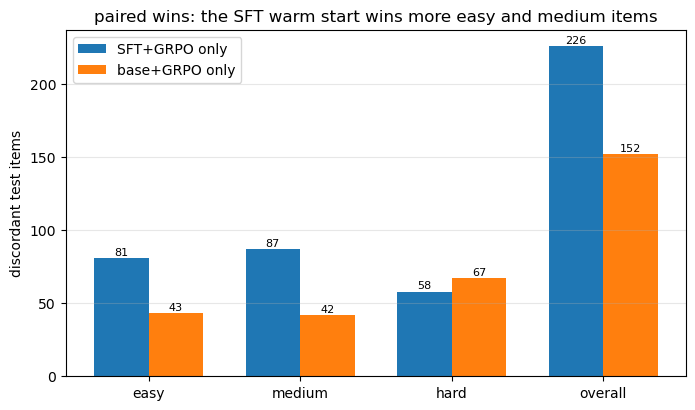

In [8]:
# count questions that only one of the two models got right
xpos = np.arange(len(GROUPS)); width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
sft_only = [row["n_sft_grpo_only"] for row in rq3_stats]
base_only = [row["n_base_grpo_only"] for row in rq3_stats]
bars1 = ax.bar(xpos - width / 2, sft_only, width, label="SFT+GRPO only")
bars2 = ax.bar(xpos + width / 2, base_only, width, label="base+GRPO only")
for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                f"{int(bar.get_height())}", ha="center", fontsize=8)
ax.set_xticks(xpos); ax.set_xticklabels(GROUPS); ax.set_ylabel("discordant test items")
ax.set_title("paired wins: the SFT warm start wins more easy and medium items")
ax.grid(alpha=0.3, axis="y"); ax.legend()
save(fig, "fig07_rq3_discordant_pairs")
plt.show()

## 3. Mechanism: expression changes while the knowledge probe stays flat

The log-probability probe measures the model's preference among the four answer letters without
free-form generation or extraction. If that probe stays flat while generative accuracy moves,
the main effect is improved expression and elicitation rather than new encoded knowledge.

saved fig08_knowledge_probe


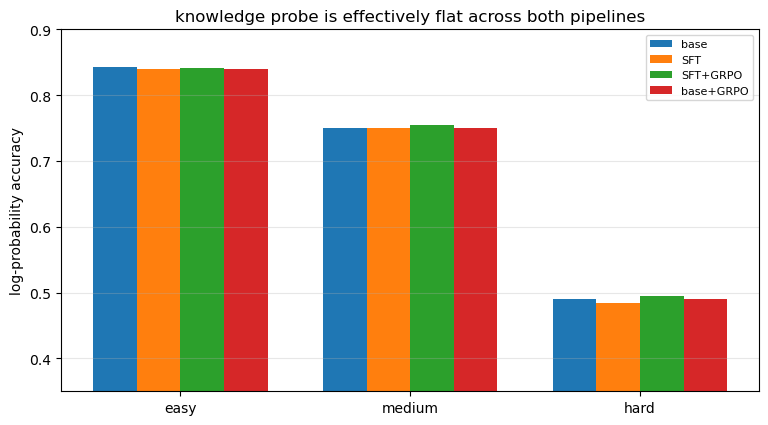

In [9]:
# put all stages on the same logprob knowledge scale
conditions = [
    ("base", D4, "base"),
    ("SFT", D3, "sft"),
    ("SFT+GRPO", D3, "sft_grpo"),
    ("base+GRPO", D4, "base_grpo"),
]
xpos = np.arange(len(TIERS)); width = 0.19
fig, ax = plt.subplots(figsize=(9, 4.7))
for i, (label, D, condition) in enumerate(conditions):
    values = [D["lp"][condition]["per_tier_acc"][tier] for tier in TIERS]
    ax.bar(xpos + (i - 1.5) * width, values, width, label=label)
ax.set_xticks(xpos); ax.set_xticklabels(TIERS); ax.set_ylim(0.35, 0.9)
ax.set_ylabel("log-probability accuracy")
ax.set_title("knowledge probe is effectively flat across both pipelines")
ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
save(fig, "fig08_knowledge_probe")
plt.show()

saved fig09_gap_to_ceiling


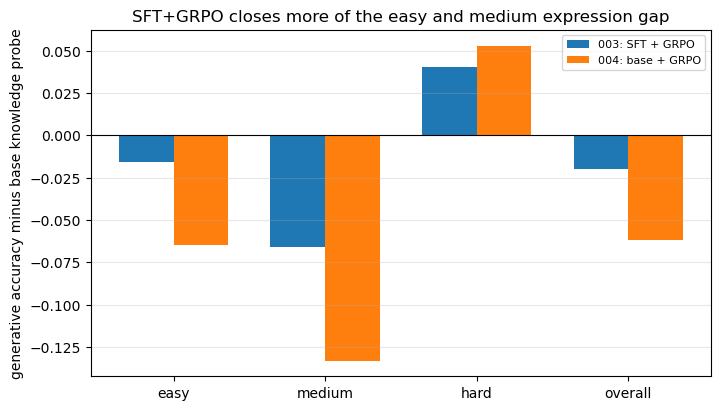

In [10]:
# compare each grpo result against its own base knowledge score
xpos = np.arange(len(GROUPS)); width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (D, condition, label) in enumerate([
    (D3, "sft_grpo", "003: SFT + GRPO"),
    (D4, "base_grpo", "004: base + GRPO"),
]):
    gaps = []
    for group in GROUPS:
        if group == "overall":
            gaps.append(overall(D, condition) - overall(D, "base", probe=True))
        else:
            gaps.append(D["eval"][condition]["per_tier_acc"][group]
                        - D["lp"]["base"]["per_tier_acc"][group])
    ax.bar(xpos + (i - 0.5) * width, gaps, width, label=label)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos); ax.set_xticklabels(GROUPS)
ax.set_ylabel("generative accuracy minus base knowledge probe")
ax.set_title("SFT+GRPO closes more of the easy and medium expression gap")
ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
save(fig, "fig09_gap_to_ceiling")
plt.show()

saved fig10_eval_diagnostics


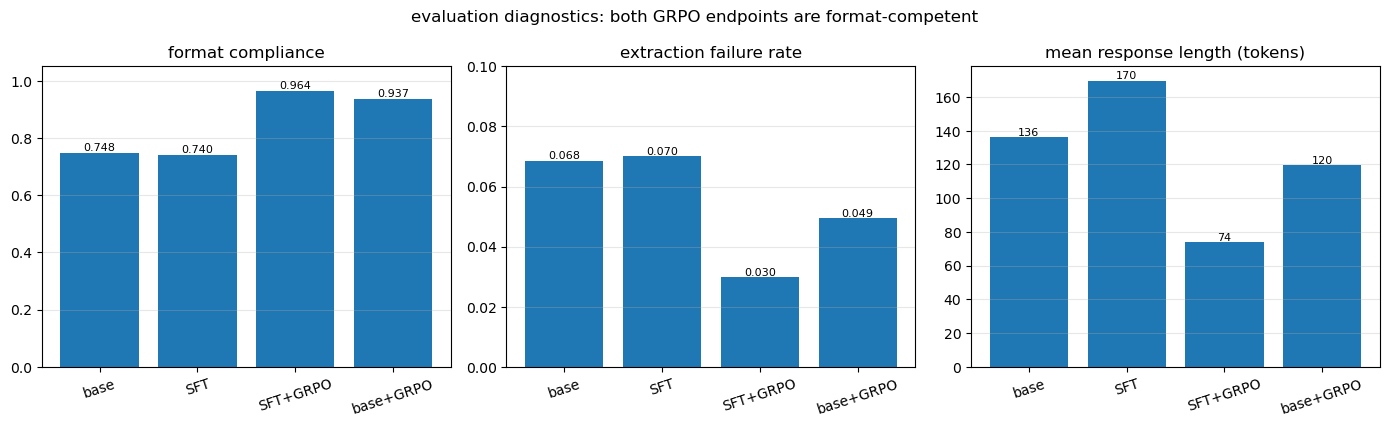

In [11]:
# compare format, extraction failures and answer length
diag_conditions = [
    ("base", D4, "base"),
    ("SFT", D3, "sft"),
    ("SFT+GRPO", D3, "sft_grpo"),
    ("base+GRPO", D4, "base_grpo"),
]
metrics = [
    ("format_compliance", "format compliance"),
    ("extraction_failure_rate", "extraction failure rate"),
    ("mean_len", "mean response length (tokens)"),
]
xpos = np.arange(len(diag_conditions))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (key, title) in zip(axes, metrics):
    values = [D["eval"][condition][key] for _, D, condition in diag_conditions]
    bars = ax.bar(xpos, values)
    for bar, value in zip(bars, values):
        label = f"{value:.0f}" if key == "mean_len" else f"{value:.3f}"
        ax.text(bar.get_x() + bar.get_width() / 2, value, label,
                ha="center", va="bottom", fontsize=8)
    ax.set_xticks(xpos); ax.set_xticklabels([row[0] for row in diag_conditions], rotation=18)
    ax.set_title(title); ax.grid(alpha=0.3, axis="y")
    if key == "format_compliance":
        ax.set_ylim(0, 1.05)
    elif key == "extraction_failure_rate":
        ax.set_ylim(0, 0.10)
fig.suptitle("evaluation diagnostics: both GRPO endpoints are format-competent")
fig.tight_layout()
save(fig, "fig10_eval_diagnostics")
plt.show()

## 4. What the two GRPO endpoints write

saved fig11_length_and_think


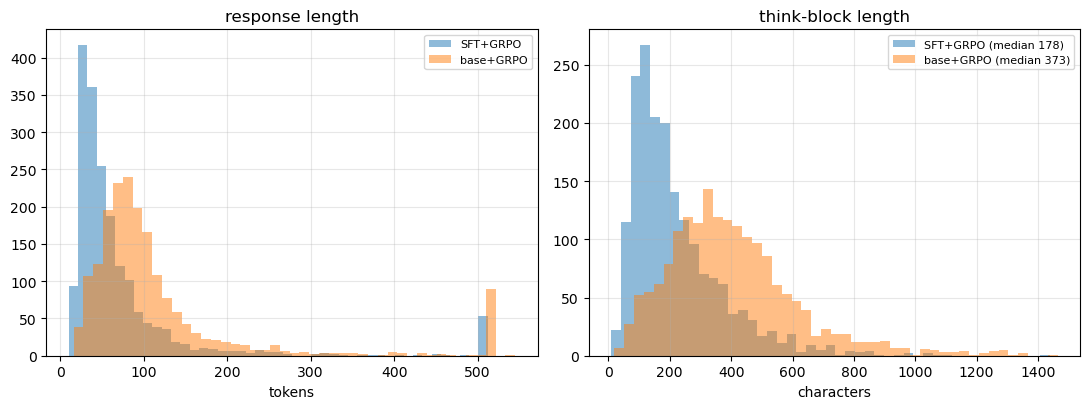

In [12]:
# compare final answer lengths and the text inside think
def think_lengths(rows):
    lengths = []
    for row in rows:
        match = re.search(r"(.*?)</think>", "<think>" + row["output"], re.DOTALL)
        if match:
            text = match.group(1).replace("<think>", "").strip()
            lengths.append(len(text))
    return lengths

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for D, condition, label in [
    (D3, "sft_grpo", "SFT+GRPO"),
    (D4, "base_grpo", "base+GRPO"),
]:
    axes[0].hist([row["n_tokens"] for row in D["preds"][condition]],
                 bins=45, alpha=0.5, label=label)
    lengths = think_lengths(D["preds"][condition])
    axes[1].hist(lengths, bins=45, alpha=0.5,
                 label=f"{label} (median {np.median(lengths):.0f})")
axes[0].set_title("response length"); axes[0].set_xlabel("tokens")
axes[1].set_title("think-block length"); axes[1].set_xlabel("characters")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig11_length_and_think")
plt.show()

saved fig12_per_subject_rq3_delta


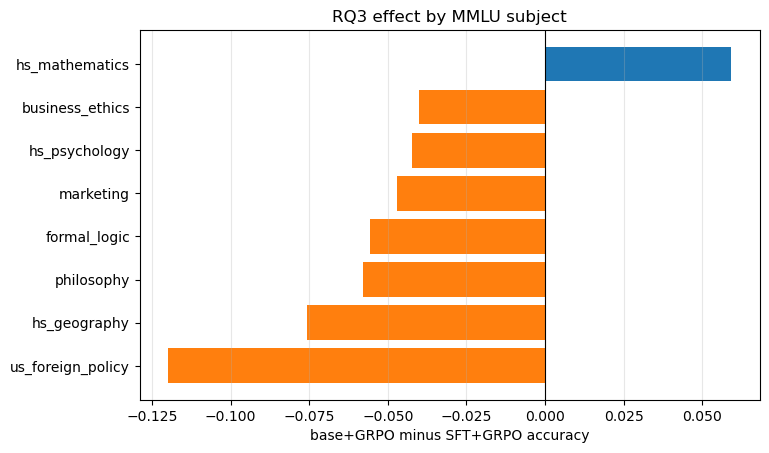

In [13]:
# check which subjects get better or worse without sft
subjects = list(D3["eval"]["sft_grpo"]["per_subject_acc"])
deltas = [D4["eval"]["base_grpo"]["per_subject_acc"][subject]
          - D3["eval"]["sft_grpo"]["per_subject_acc"][subject]
          for subject in subjects]
order = np.argsort(deltas)
labels = [subjects[i].replace("high_school_", "hs_") for i in order]
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = ["tab:blue" if deltas[i] >= 0 else "tab:orange" for i in order]
ax.barh(labels, [deltas[i] for i in order], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("base+GRPO minus SFT+GRPO accuracy")
ax.set_title("RQ3 effect by MMLU subject")
ax.grid(alpha=0.3, axis="x")
save(fig, "fig12_per_subject_rq3_delta")
plt.show()

## 5. Compute

The 003 base evaluation was already cached, while 004 recomputed it under its own experiment key.
The stage bars therefore describe measured wall-clock cost rather than an ideal shared-cache plan.

saved fig13_compute_comparison


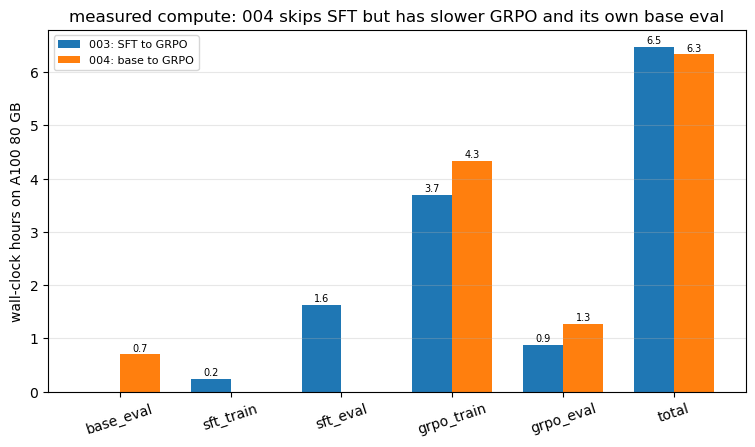

In [14]:
# compare the measured a100 hours for both runs
stages = ["base_eval", "sft_train", "sft_eval", "grpo_train", "grpo_eval", "total"]
xpos = np.arange(len(stages)); width = 0.36
fig, ax = plt.subplots(figsize=(9, 4.7))
for i, (D, label) in enumerate([(D3, "003: SFT to GRPO"), (D4, "004: base to GRPO")]):
    timings = D["man"]["timings_sec"]
    values = [timings.get(stage, 0) / 3600 for stage in stages[:-1]]
    values.append(sum(timings.values()) / 3600)
    bars = ax.bar(xpos + (i - 0.5) * width, values, width, label=label)
    for bar, value in zip(bars, values):
        if value >= 0.1:
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.06, f"{value:.1f}",
                    ha="center", fontsize=7)
ax.set_xticks(xpos); ax.set_xticklabels(stages, rotation=18)
ax.set_ylabel("wall-clock hours on A100 80 GB")
ax.set_title("measured compute: 004 skips SFT but has slower GRPO and its own base eval")
ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
save(fig, "fig13_compute_comparison")
plt.show()

## 6. Metrics tables

Every value below is computed directly from the saved artifacts. These tables are the numeric
source of truth for the plots and the 004 results memo.

In [15]:
import pandas as pd

# collect accuracy and logprob numbers for the main conditions
accuracy_conditions = [
    ("base (004)", D4, "base"),
    ("SFT (003)", D3, "sft"),
    ("SFT+GRPO (003)", D3, "sft_grpo"),
    ("base+GRPO (004)", D4, "base_grpo"),
]
rows = []
for label, D, condition in accuracy_conditions:
    gen = D["eval"][condition]["per_tier_acc"]
    probe = D["lp"][condition]["per_tier_acc"]
    rows.append({
        "condition": label,
        "gen_easy": gen["easy"],
        "gen_medium": gen["medium"],
        "gen_hard": gen["hard"],
        "gen_overall": overall(D, condition),
        "probe_easy": probe["easy"],
        "probe_medium": probe["medium"],
        "probe_hard": probe["hard"],
        "probe_overall": overall(D, condition, probe=True),
    })
accuracy_tbl = pd.DataFrame(rows).set_index("condition").round(4)
display(accuracy_tbl)

,gen_easy,gen_medium,gen_hard,gen_overall,probe_easy,probe_medium,probe_hard,probe_overall
condition,,,,,,,,
base (004),0.6780,0.5353,0.5076,0.5961,0.8430,0.7504,0.4899,0.7389
SFT (003),0.6086,0.4877,0.4394,0.5340,0.8396,0.7504,0.4848,0.7362
SFT+GRPO (003),0.8214,0.6913,0.5202,0.7160,0.8419,0.7553,0.4949,0.7410
base+GRPO (004),0.7782,0.6174,0.5429,0.6768,0.8396,0.7504,0.4899,0.7373


In [ ]:
# keep the paired rq3 results in one table for the memo
rq3_tbl = pd.DataFrame(rq3_stats).set_index("tier")
display(rq3_tbl.round({
    "delta": 4,
    "ci_lo": 4,
    "ci_hi": 4,
    "mcnemar_p": 6,
}))

,delta,ci_lo,ci_hi,mcnemar_p,n_sft_grpo_only,n_base_grpo_only
tier,,,,,,
easy,-0.0432,-0.0683,-0.0182,0.000820,81,43
medium,-0.0739,-0.1100,-0.0378,0.000092,87,42
hard,0.0227,-0.0328,0.0758,0.474422,58,67
overall,-0.0393,-0.0594,-0.0191,0.000166,226,152


In [17]:
# summarise where both grpo runs started and ended
def head_mean(log, key, count=20):
    values = [row[key] for row in log if key in row]
    return float(np.mean(values[:count]))

def tail_mean(log, key, count=20):
    values = [row[key] for row in log if key in row]
    return float(np.mean(values[-count:]))

def median_value(log, key):
    return float(np.median([row[key] for row in log if key in row]))

rows = []
for label, D in [("003: SFT to GRPO", D3), ("004: base to GRPO", D4)]:
    log = D["g"]
    rows.append({
        "run": label,
        "acc_reward_start20": head_mean(log, "rewards/accuracy_reward/mean"),
        "acc_reward_end20": tail_mean(log, "rewards/accuracy_reward/mean"),
        "format_reward_end20": tail_mean(log, "rewards/format_reward/mean"),
        "length_end20": tail_mean(log, "completions/mean_length"),
        "clipped_end20": tail_mean(log, "completions/clipped_ratio"),
        "kl_late50": tail_mean(log, "kl", 50),
        "kl_median": median_value(log, "kl"),
        "zero_std_late50": tail_mean(log, "frac_reward_zero_std", 50),
    })
training_tbl = pd.DataFrame(rows).set_index("run").round(4)
display(training_tbl)

,acc_reward_start20,acc_reward_end20,format_reward_end20,length_end20,clipped_end20,kl_late50,kl_median,zero_std_late50
run,,,,,,,,
003: SFT to GRPO,0.3688,0.6562,0.1850,90.9500,0.0188,0.0221,0.0138,0.32
004: base to GRPO,0.3875,0.6562,0.1875,109.8688,0.0125,0.0280,0.0186,0.36


In [18]:
# put format, extraction and response length into one table
rows = []
for label, D, condition in accuracy_conditions:
    evaluation = D["eval"][condition]
    rows.append({
        "condition": label,
        "format_compliance": evaluation["format_compliance"],
        "extraction_failure_rate": evaluation["extraction_failure_rate"],
        "mean_length_tokens": evaluation["mean_len"],
    })
diagnostics_tbl = pd.DataFrame(rows).set_index("condition").round(4)
display(diagnostics_tbl)

,format_compliance,extraction_failure_rate,mean_length_tokens
condition,,,
base (004),0.7484,0.0685,136.0138
SFT (003),0.7404,0.0701,169.6799
SFT+GRPO (003),0.9644,0.0297,73.7001
base+GRPO (004),0.9374,0.0494,119.5042


In [19]:
# put measured run times from both manifests into one table
rows = []
for label, D in [("003: SFT to GRPO", D3), ("004: base to GRPO", D4)]:
    timings = D["man"]["timings_sec"]
    row = {"run": label}
    row.update({key: value / 3600 for key, value in timings.items()})
    row["total_h"] = sum(timings.values()) / 3600
    rows.append(row)
compute_tbl = pd.DataFrame(rows).set_index("run").fillna(0).round(3)
display(compute_tbl)

,sft_train,sft_eval,sft_logprob_eval,grpo_train,grpo_eval,grpo_logprob_eval,total_h,base_eval,base_logprob_eval
run,,,,,,,,,
003: SFT to GRPO,0.243,1.632,0.01,3.701,0.874,0.010,6.469,0.000,0.000
004: base to GRPO,0.000,0.000,0.00,4.335,1.281,0.008,6.330,0.701,0.005


In [ ]:
# keep the subject comparison as a table too
rows = []
for subject in subjects:
    sft_grpo = D3["eval"]["sft_grpo"]["per_subject_acc"][subject]
    base_grpo = D4["eval"]["base_grpo"]["per_subject_acc"][subject]
    rows.append({
        "subject": subject,
        "SFT+GRPO": sft_grpo,
        "base+GRPO": base_grpo,
        "base_minus_sft": base_grpo - sft_grpo,
    })
subject_tbl = pd.DataFrame(rows).set_index("subject").sort_values("base_minus_sft").round(4)
display(subject_tbl)

,SFT+GRPO,base+GRPO,base_minus_sft
subject,,,
us_foreign_policy,0.7900,0.6700,-0.1200
high_school_geography,0.6869,0.6111,-0.0758
philosophy,0.6624,0.6045,-0.0579
formal_logic,0.4683,0.4127,-0.0556
marketing,0.8205,0.7735,-0.0470
high_school_psychology,0.8404,0.7982,-0.0422
business_ethics,0.7200,0.6800,-0.0400
high_school_mathematics,0.5444,0.6037,0.0593


## 7. Accuracy overview

saved fig14_accuracy_overview


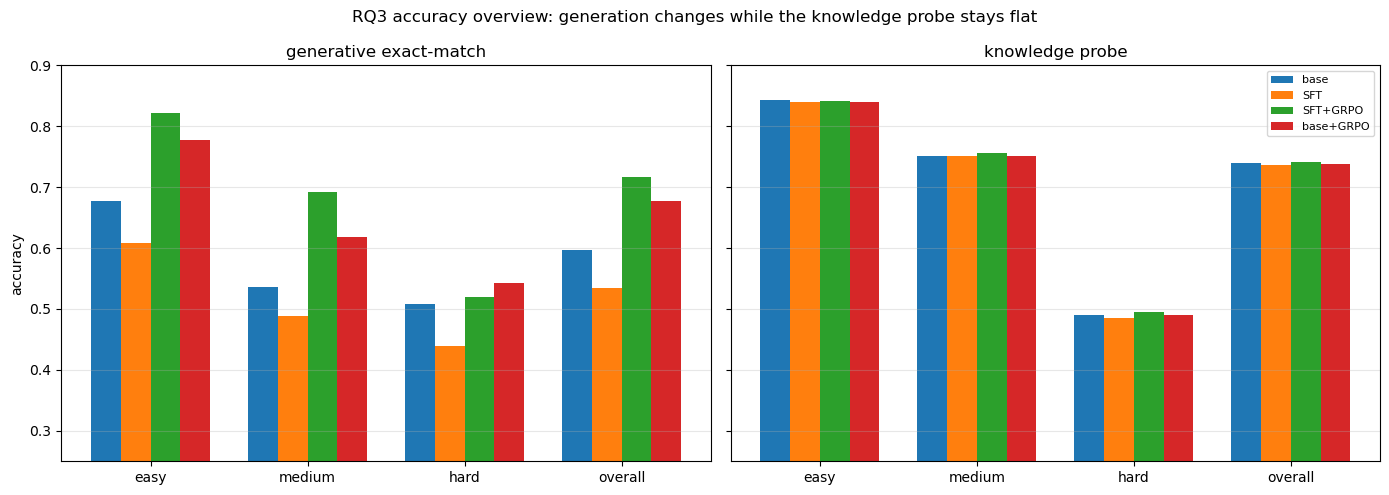

In [21]:
# plot the full accuracy table as generative and logprob panels
labels = [row[0] for row in accuracy_conditions]
short_labels = ["base", "SFT", "SFT+GRPO", "base+GRPO"]
xpos = np.arange(len(GROUPS)); width = 0.19
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, probe, title in [
    (axes[0], False, "generative exact-match"),
    (axes[1], True, "knowledge probe"),
]:
    for i, ((_, D, condition), short) in enumerate(zip(accuracy_conditions, short_labels)):
        source = D["lp"] if probe else D["eval"]
        values = [source[condition]["per_tier_acc"][tier] for tier in TIERS]
        values.append(overall(D, condition, probe=probe))
        ax.bar(xpos + (i - 1.5) * width, values, width, label=short)
    ax.axhline(0.25, color="grey", lw=0.7, ls="--")
    ax.set_xticks(xpos); ax.set_xticklabels(GROUPS); ax.set_ylim(0.25, 0.9)
    ax.set_title(title); ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("accuracy"); axes[1].legend(fontsize=8)
fig.suptitle("RQ3 accuracy overview: generation changes while the knowledge probe stays flat")
fig.tight_layout()
save(fig, "fig14_accuracy_overview")
plt.show()